In [1]:
#running simulation environment of the price with brownian motion
import sys
sys.path.append("..")

import numpy as np
from src.simulation import simulate_gbm
    

In [2]:
#testing a function
S = simulate_gbm(S0 = 100, mu = 0.0, sigma = 0.2, T = 30/365, n_steps = 30, n_paths= 100_000, seed = 42 )
print(S.shape)
print(S[:3, :5])

(100000, 31)
[[100.         100.31400493  99.22236772  99.99945716 100.98340986]
 [100.         102.26169687 101.82196447 101.27186622 100.40729747]
 [100.          98.24833515  97.89914091  98.06070804  98.65893667]]


In [3]:
S_T = S[:, -1]
print(S_T.mean()) # actual
print(100*np.exp(0.0 * 30/365)) # emperica

100.01952131630898
100.0


In [4]:
print(np.log(S_T).var()) # emperical
print(0.2**2 * 30/365) # theoretical

0.003257567534857781
0.003287671232876713


In [5]:
#testing for a dreif 
S_test = simulate_gbm(S0 = 100, mu = 0.5, sigma = 0.2, T = 30/365, n_steps = 30, n_paths= 100_000, seed = 42 )
S_t_Test = S_test[:, -1]
print(S_t_Test.mean()) # actual
print(100*np.exp(0.5* 30/365)) # empirical



104.2155416710525
104.19520139620917


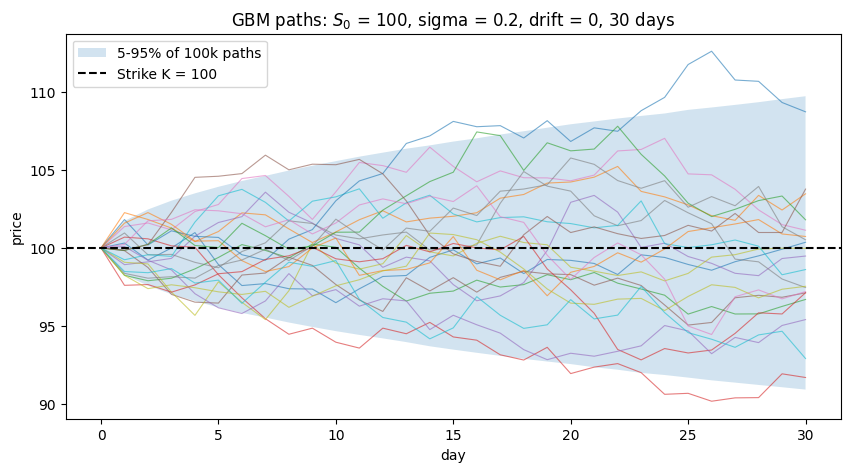

In [6]:
#visualizing all paths

import matplotlib.pyplot as plt


S = simulate_gbm(S0 = 100, mu = 0.0, sigma = 0.2, T = 30/365, n_steps = 30, n_paths= 100_000, seed = 42 )

days = np.linspace(0,30,31)
low,high = np.percentile(S,[5,95], axis = 0)


plt.figure(figsize=(10,5))
plt.fill_between(days,low,high, alpha = 0.2, label = "5-95% of 100k paths")
plt.plot(days,S[:20].T, lw = 0.8, alpha = 0.6)
plt.axhline(100,ls="--",color = "black", label = "Strike K = 100")
plt.xlabel("day")
plt.ylabel("price")
plt.title("GBM paths: $S_0$ = 100, sigma = 0.2, drift = 0, 30 days")
plt.legend()
plt.savefig("gbm_paths.png", dpi = 150, bbox_inches = "tight")
plt.show()